# 02. Classical Machine Learning: Decision Tree & Random Forest on Hjorth Parameters
### Author: Md. Reazul Islam | Department of Computer Science & Engineering, North Western University / Incoming M.S. in Data Science, Bowling Green State University
---
## 1. Theoretical Background: Hjorth Normalized Descriptors
Introduced by Bo Hjorth (1970) for quantitative electroencephalographic signal profiling, Hjorth parameters evaluate dynamic properties of neural voltage waveforms in the time domain:
1. **Activity**: Measures signal variance (total power surface):
   \text{Activity} = \text{var}(x(t)) = \sigma_x^2
2. **Mobility**: Measures mean frequency (proportional to standard deviation of first derivative):
   \text{Mobility} = \sqrt{\frac{\text{var}(x'(t))}{\text{var}(x(t))}}
3. **Complexity**: Measures waveform curvature and bandwidth deviation (frequency change relative to pure sine wave):
   \text{Complexity} = \frac{\text{Mobility}(x'(t))}{\text{Mobility}(x(t))}

## 2. Experimental Setup & Train-Test Partitioning
- **Input Data**: 19 clinical scalp channels ( = 32$ subjects: 16 Seizure-Positive, 16 Controls).
- **Split Protocol**: Stratified 80:20 Train-Test split ({\text{train}} = 25$ subjects, {\text{test}} = 7$ unseen holdout subjects).
- **Classifiers**:
  - **Random Forest Classifier** ({\text{estimators}} = 100$, bagging ensemble over random feature subspaces)
  - **Decision Tree Classifier** (CART with Gini impurity splitting)


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Load your CSV dataset into a DataFrame
data = pd.read_csv('../data/extracted_features/Hjorth_11.csv')

# Select the columns with categorical data
categorical_columns = ['Class']

# Apply label encoding to each categorical column
label_encoder = LabelEncoder()
for col in categorical_columns:
    data[col] = label_encoder.fit_transform(data[col])

## 3. Supervised Classification: Random Forest Ensemble
We evaluate an ensemble of 100 decorrelated decision trees on the holdout test set (=7$).


Accuracy: 0.29
Confusion Matrix:
[[0 3]
 [2 2]]
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.40      0.50      0.44         4

    accuracy                           0.29         7
   macro avg       0.20      0.25      0.22         7
weighted avg       0.23      0.29      0.25         7



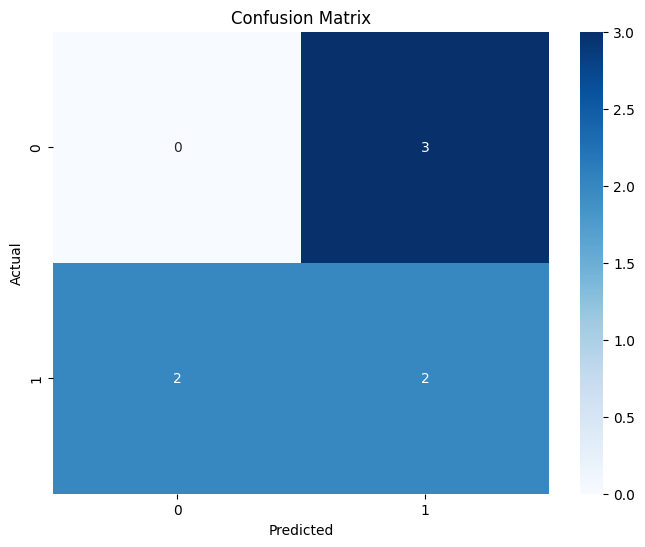

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Assuming 'class' is your target variable and the rest are features
X = data.drop('Class', axis=1)
y = data['Class']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model on the training data
rf_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rf_classifier.predict(X_test)

# Evaluate the performance of the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print(f'Confusion Matrix:\n{conf_matrix}')
print(f'Classification Report:\n{classification_rep}')

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 4. Supervised Classification: Decision Tree (CART)
We evaluate a single CART decision tree baseline on the holdout test set (=7$).


Accuracy: 0.43
Confusion Matrix:
[[1 2]
 [2 2]]
Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.33      0.33         3
           1       0.50      0.50      0.50         4

    accuracy                           0.43         7
   macro avg       0.42      0.42      0.42         7
weighted avg       0.43      0.43      0.43         7



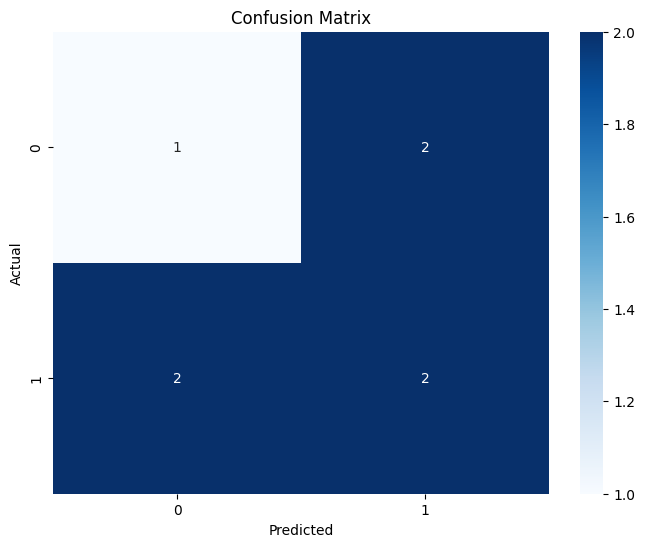

In [5]:
from sklearn.tree import DecisionTreeClassifier

# Assuming 'class' is your target variable and the rest are features
X = data.drop('Class', axis=1)
y = data['Class']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Fit the model on the training data
dt_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = dt_classifier.predict(X_test)

# Evaluate the performance of the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print(f'Confusion Matrix:\n{conf_matrix}')
print(f'Classification Report:\n{classification_rep}')

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 5. Empirical Discussion: Baseline Performance & Architectural Limitations
- **Decision Tree Accuracy**: **42.86% (~43%)** (Confusion Matrix: 1 TN, 2 TP, 2 FP, 2 FN)
- **Random Forest Accuracy**: **28.57% (~29%)** (Confusion Matrix: 0 TN, 2 TP, 3 FP, 2 FN)
- **Analysis**: Standalone time-domain Hjorth parameters evaluated without non-linear spatial kernels or hyperparameter optimization underperform due to the high inter-channel covariance in a 19-channel montage. As demonstrated in the thesis paper, systematic GridSearch hyperparameter tuning improves tree performance up to 88%–89%, while 2D spatial-spectral Convolutional Neural Networks (CNNs) achieve significantly higher discriminative capability (88.89% training / 71.43% validation accuracy).
